# Exercise: Ensemble

Anda bekerja sebagai data scientist di perusahaan asuransi. Anda diminta untuk memprediksi apakah seorang calon nasabah akan mengajukan klaim ketika dia memiliki asuransi atau tidak. 

- Dataset: Car_Insurance_Claim.csv
- Target: 'OUTCOME'


In [100]:
# import libraries
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msn

from matplotlib.colors import ListedColormap

from collections import Counter

from statsmodels.stats.outliers_influence import variance_inflation_factor

from category_encoders import OrdinalEncoder, BinaryEncoder
from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler,OneHotEncoder,KBinsDiscretizer,PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier,DecisionTreeRegressor,plot_tree
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge
from sklearn.ensemble import VotingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from xgboost.sklearn import XGBClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score, recall_score, precision_score, mean_squared_error, RocCurveDisplay, mean_absolute_percentage_error, PrecisionRecallDisplay
from sklearn.metrics._scorer import _SCORERS

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

## Load Dataset

In [101]:
df = pd.read_csv('Car_Insurance_Claim.csv')
df.head()

,ID,AGE,GENDER,RACE,DRIVING_EXPERIENCE,EDUCATION,INCOME,CREDIT_SCORE,VEHICLE_OWNERSHIP,VEHICLE_YEAR,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,VEHICLE_TYPE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
0,569520,65+,female,majority,0-9y,high school,upper class,0.629027,1.0,after 2015,0.0,1.0,10238,12000.0,sedan,0,0,0,0.0
1,750365,16-25,male,majority,0-9y,none,poverty,0.357757,0.0,before 2015,0.0,0.0,10238,16000.0,sedan,0,0,0,1.0
2,199901,16-25,female,majority,0-9y,high school,working class,0.493146,1.0,before 2015,0.0,0.0,10238,11000.0,sedan,0,0,0,0.0
3,478866,16-25,male,majority,0-9y,university,working class,0.206013,1.0,before 2015,0.0,1.0,32765,11000.0,sedan,0,0,0,0.0
4,731664,26-39,male,majority,10-19y,none,working class,0.388366,1.0,before 2015,0.0,0.0,32765,12000.0,sedan,2,0,1,1.0


In [102]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   10000 non-null  int64  
 1   AGE                  10000 non-null  object 
 2   GENDER               10000 non-null  object 
 3   RACE                 10000 non-null  object 
 4   DRIVING_EXPERIENCE   10000 non-null  object 
 5   EDUCATION            10000 non-null  object 
 6   INCOME               10000 non-null  object 
 7   CREDIT_SCORE         9018 non-null   float64
 8   VEHICLE_OWNERSHIP    10000 non-null  float64
 9   VEHICLE_YEAR         10000 non-null  object 
 10  MARRIED              10000 non-null  float64
 11  CHILDREN             10000 non-null  float64
 12  POSTAL_CODE          10000 non-null  int64  
 13  ANNUAL_MILEAGE       9043 non-null   float64
 14  VEHICLE_TYPE         10000 non-null  object 
 15  SPEEDING_VIOLATIONS  10000 non-null  

In [103]:
df.isna().sum()[df.isna().sum()>0]

CREDIT_SCORE      982
ANNUAL_MILEAGE    957
dtype: int64

In [104]:
df.duplicated().sum()

0

## EDA

In [105]:
pd.set_option('display.max_colwidth', None)
# data uni di tiap kolom
listItem = []
for col in df.columns :
    listItem.append( [col, df[col].nunique(), df.sort_values(col)[col].unique()])

tabel1Desc = pd.DataFrame(columns=['Column Name', 'Number of Unique', 'Unique Sample'],
                     data=listItem)
tabel1Desc

,Column Name,Number of Unique,Unique Sample
0,ID,10000,"[101, 125, 166, 186, 217, 226, 244, 286, 381, 542, 603, 775, 793, 864, 938, 1003, 1063, 1126, 1860, 1924, 2087, 2375, 2387, 2590, 2654, 2698, 2743, 2906, 3004, 3025, 3038, 3114, 3131, 3141, 3170, 3308, 3396, 3413, 3526, 3626, 3643, 3794, 3856, 4035, 4199, 4334, 4427, 4617, 4674, 4747, 4953, 4968, 5003, 5017, 5195, 5306, 5356, 5362, 5451, 5473, 5656, 5924, 5949, 6140, 6153, 6167, 6452, 6676, 6708, 7002, 7048, 7136, 7184, 7229, 7296, 7722, 7866, 7893, 7905, 7967, 8023, 8055, 8309, 8316, 8388, 8464, 8488, 8539, 8605, 8618, 8852, 8982, 9013, 9128, 9204, 9251, 9289, 9402, 9519, 9574, ...]"
1,AGE,4,"[16-25, 26-39, 40-64, 65+]"
2,GENDER,2,"[female, male]"
3,RACE,2,"[majority, minority]"
4,DRIVING_EXPERIENCE,4,"[0-9y, 10-19y, 20-29y, 30y+]"
5,EDUCATION,3,"[high school, none, university]"
6,INCOME,4,"[middle class, poverty, upper class, working class]"
7,CREDIT_SCORE,9018,"[0.0533575454627435, 0.0608666163116088, 0.0648103533102058, 0.0953870936940878, 0.0972109997290097, 0.0996552260693457, 0.1126311166194294, 0.1154024763653657, 0.1162638006141908, 0.1184454426595448, 0.11914479835417, 0.1218260842948218, 0.1237946155140384, 0.123977548630641, 0.125876021475771, 0.1258955435359577, 0.1264534313986037, 0.1274177169396, 0.132881119448434, 0.1342465210434547, 0.1353164145309943, 0.1364496536239104, 0.1409830759792809, 0.1412946066838692, 0.1428568741606682, 0.1436568483193364, 0.1492983955982136, 0.1501006461161934, 0.1512554855508021, 0.1529047455785444, 0.1529721602255696, 0.1541351795574787, 0.1555965806036122, 0.1562510004957406, 0.1565732779409757, 0.1566679166032045, 0.1572774333743463, 0.1573968220490889, 0.1584752834539108, 0.1592498162888258, 0.1597997577289595, 0.160705687872896, 0.1607846136059094, 0.160804993390916, 0.1615453690910059, 0.1645111021901411, 0.1658168281115772, 0.1665624379563555, 0.1676097239171405, 0.1693395631005956, 0.1694065530970372, 0.1695337483643942, 0.1696797792669734, 0.1702452857312173, 0.1705500566934862, 0.1712440288213211, 0.1717780113795827, 0.1719461465592734, 0.1732536697645697, 0.1747592446844146, 0.175240246078814, 0.1760594297090703, 0.1761149663789997, 0.1774430776316491, 0.178051021339576, 0.1795257577369365, 0.1853336147606677, 0.186185114720855, 0.1871101619206013, 0.1875823533910216, 0.1882012501796915, 0.1882399427662648, 0.1902502054363816, 0.1909109064399252, 0.1921586821692091, 0.1922339121015746, 0.1924274124285441, 0.1926279254414204, 0.1931346926606078, 0.1932637946609026, 0.19362266071106, 0.19414954837432, 0.1942253046228653, 0.1950515541346116, 0.1952385586730968, 0.1958165116504413, 0.1961267039783941, 0.196580683690525, 0.1966518580351812, 0.1968910724089191, 0.1978523331797128, 0.1986636668256905, 0.1986688491150986, 0.1991659324100259, 0.1992925327715535, 0.1995060079109585, 0.1995862649955144, 0.1999177653736918, 0.2000544061533787, 0.2004533927670908, ...]"
8,VEHICLE_OWNERSHIP,2,"[0.0, 1.0]"
9,VEHICLE_YEAR,2,"[after 2015, before 2015]"


In [106]:
df.describe(include='object')

,AGE,GENDER,RACE,DRIVING_EXPERIENCE,EDUCATION,INCOME,VEHICLE_YEAR,VEHICLE_TYPE
count,10000,10000,10000,10000,10000,10000,10000,10000
unique,4,2,2,4,3,4,2,2
top,26-39,female,majority,0-9y,high school,upper class,before 2015,sedan
freq,3063,5010,9012,3530,4157,4336,6967,9523


In [107]:
# Categorical Features
cat_features = [feature for feature in df.columns if df[feature].dtypes == 'O']
cat_features

['AGE',
 'GENDER',
 'RACE',
 'DRIVING_EXPERIENCE',
 'EDUCATION',
 'INCOME',
 'VEHICLE_YEAR',
 'VEHICLE_TYPE']

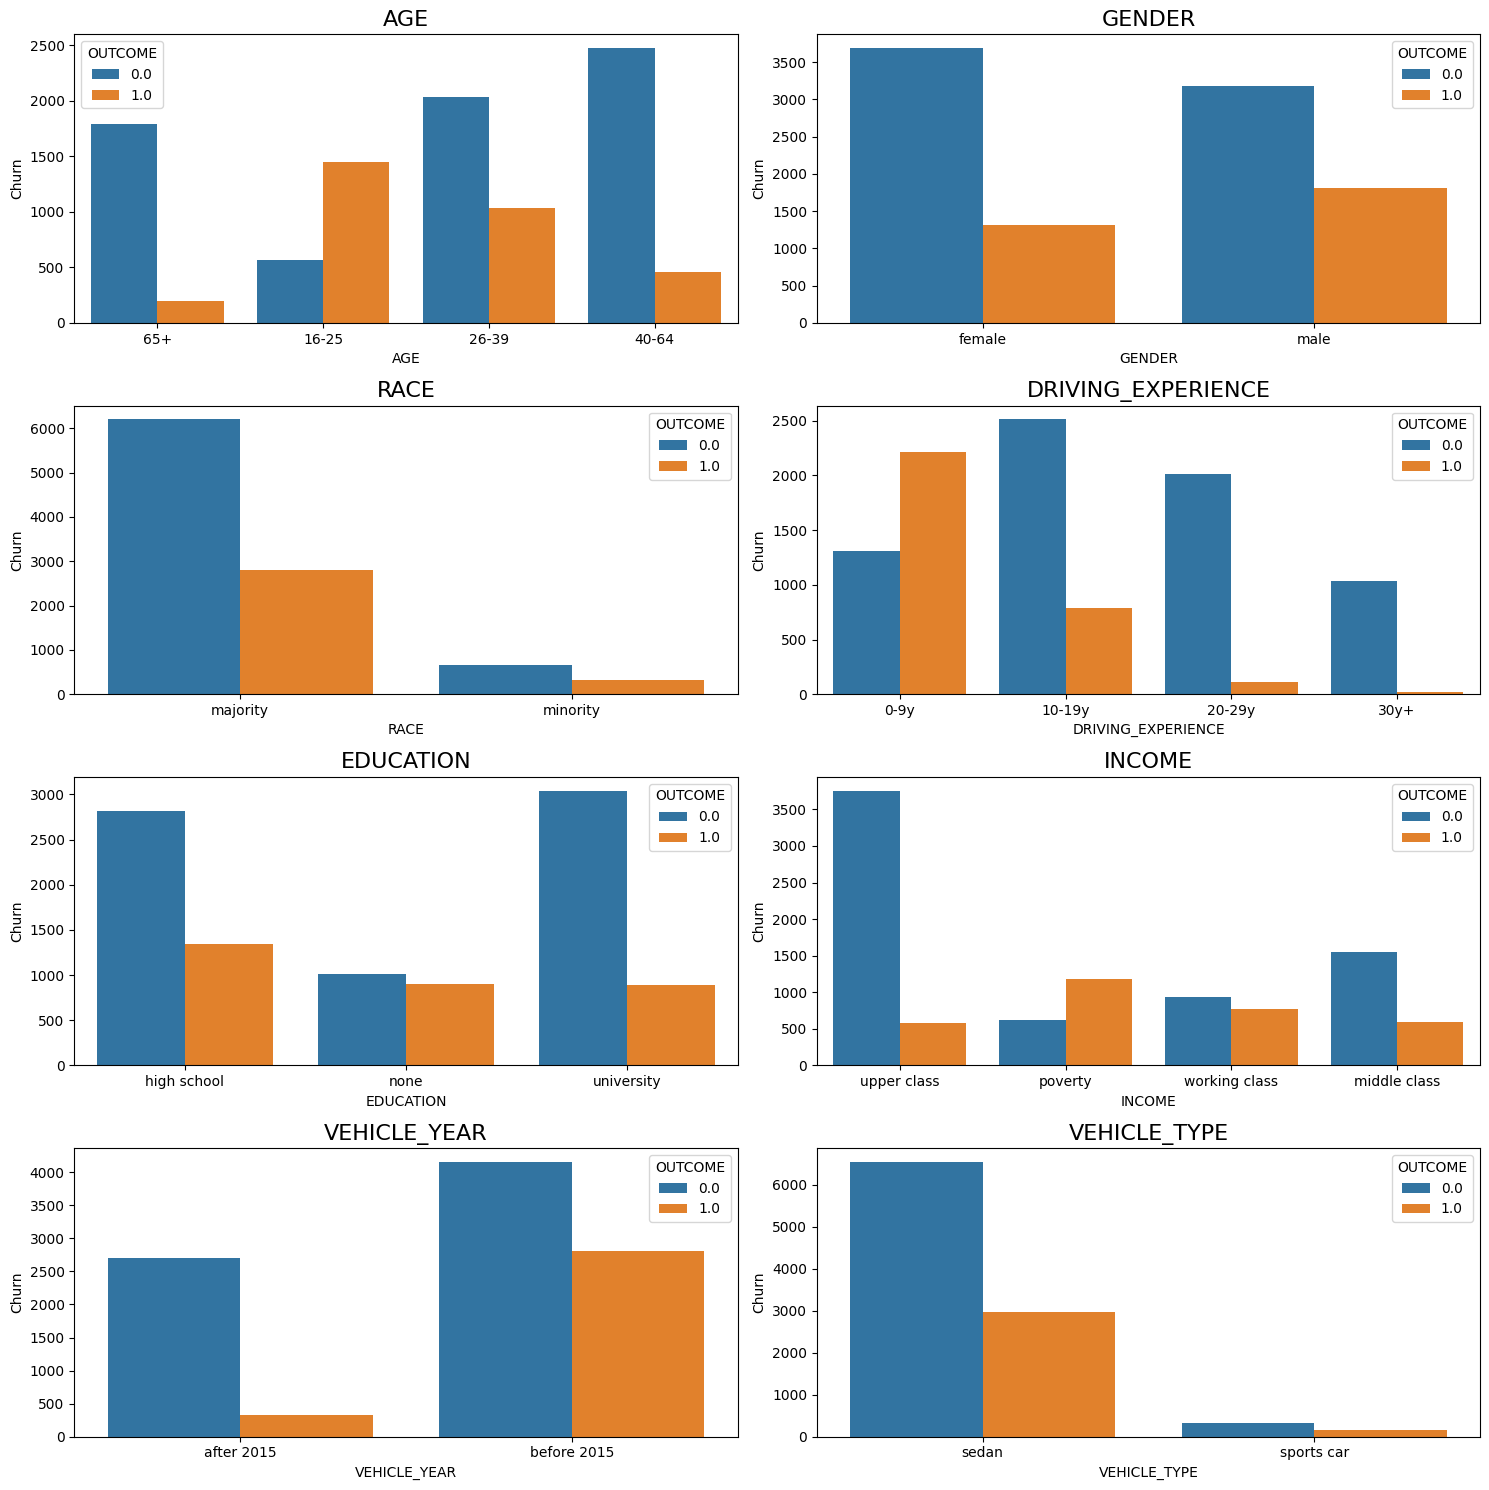

In [108]:
plt.figure(figsize=(15, 15), facecolor='white')
plotnumber = 1

for feature in cat_features:
    # subplot (letak grafik)
    ax = plt.subplot(4, 2, plotnumber)
    
    # Harga rumah berdasarkan feature 
    sns.countplot(hue = 'OUTCOME', x = feature, data = df)
    
    plt.ylabel('Churn')
    plt.xlabel(feature)
    plt.title(feature, fontsize=16)
    plt.tight_layout();
    
    plotnumber += 1

In [109]:
def create_pivot(feature):
    df_pivot = df.pivot_table(
        index = 'OUTCOME',
        columns = feature,
        values = 'ID',
        aggfunc=len
    )

    df_pivot.loc['Total'] = df_pivot.sum()
    df_pivot.loc['%'] = round(((df_pivot.loc[1] / df_pivot.loc['Total']) * 100), 1)

    return df_pivot.T.sort_values('%',ascending=False)

In [110]:
create_pivot('AGE')

OUTCOME,0.0,1.0,Total,%
AGE,,,,
16-25,568.0,1448.0,2016.0,71.8
26-39,2031.0,1032.0,3063.0,33.7
40-64,2474.0,457.0,2931.0,15.6
65+,1794.0,196.0,1990.0,9.8


In [111]:
create_pivot('GENDER')

OUTCOME,0.0,1.0,Total,%
GENDER,,,,
male,3178.0,1812.0,4990.0,36.3
female,3689.0,1321.0,5010.0,26.4


In [112]:
create_pivot('RACE')

OUTCOME,0.0,1.0,Total,%
RACE,,,,
minority,667.0,321.0,988.0,32.5
majority,6200.0,2812.0,9012.0,31.2


In [113]:
create_pivot('DRIVING_EXPERIENCE')

OUTCOME,0.0,1.0,Total,%
DRIVING_EXPERIENCE,,,,
0-9y,1313.0,2217.0,3530.0,62.8
10-19y,2512.0,787.0,3299.0,23.9
20-29y,2010.0,109.0,2119.0,5.1
30y+,1032.0,20.0,1052.0,1.9


In [114]:
create_pivot('EDUCATION')

OUTCOME,0.0,1.0,Total,%
EDUCATION,,,,
none,1012.0,903.0,1915.0,47.2
high school,2813.0,1344.0,4157.0,32.3
university,3042.0,886.0,3928.0,22.6


In [115]:
create_pivot('INCOME')

OUTCOME,0.0,1.0,Total,%
INCOME,,,,
poverty,628.0,1186.0,1814.0,65.4
working class,936.0,776.0,1712.0,45.3
middle class,1546.0,592.0,2138.0,27.7
upper class,3757.0,579.0,4336.0,13.4


In [116]:
create_pivot('VEHICLE_YEAR')

OUTCOME,0.0,1.0,Total,%
VEHICLE_YEAR,,,,
before 2015,4157.0,2810.0,6967.0,40.3
after 2015,2710.0,323.0,3033.0,10.6


In [117]:
create_pivot('VEHICLE_TYPE')

OUTCOME,0.0,1.0,Total,%
VEHICLE_TYPE,,,,
sports car,322.0,155.0,477.0,32.5
sedan,6545.0,2978.0,9523.0,31.3


In [118]:
df.describe()

,ID,CREDIT_SCORE,VEHICLE_OWNERSHIP,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
count,10000.000000,9018.000000,10000.000000,10000.000000,10000.000000,10000.000000,9043.000000,10000.000000,10000.00000,10000.000000,10000.000000
mean,500521.906800,0.515813,0.697000,0.498200,0.688800,19864.548400,11697.003207,1.482900,0.23920,1.056300,0.313300
std,290030.768758,0.137688,0.459578,0.500022,0.463008,18915.613855,2818.434528,2.241966,0.55499,1.652454,0.463858
min,101.000000,0.053358,0.000000,0.000000,0.000000,10238.000000,2000.000000,0.000000,0.00000,0.000000,0.000000
25%,249638.500000,0.417191,0.000000,0.000000,0.000000,10238.000000,10000.000000,0.000000,0.00000,0.000000,0.000000
50%,501777.000000,0.525033,1.000000,0.000000,1.000000,10238.000000,12000.000000,0.000000,0.00000,0.000000,0.000000
75%,753974.500000,0.618312,1.000000,1.000000,1.000000,32765.000000,14000.000000,2.000000,0.00000,2.000000,1.000000
max,999976.000000,0.960819,1.000000,1.000000,1.000000,92101.000000,22000.000000,22.000000,6.00000,15.000000,1.000000


In [119]:
# Numerical Features
num_feature = [feature for feature in df.describe().columns]
num_feature

['ID',
 'CREDIT_SCORE',
 'VEHICLE_OWNERSHIP',
 'MARRIED',
 'CHILDREN',
 'POSTAL_CODE',
 'ANNUAL_MILEAGE',
 'SPEEDING_VIOLATIONS',
 'DUIS',
 'PAST_ACCIDENTS',
 'OUTCOME']

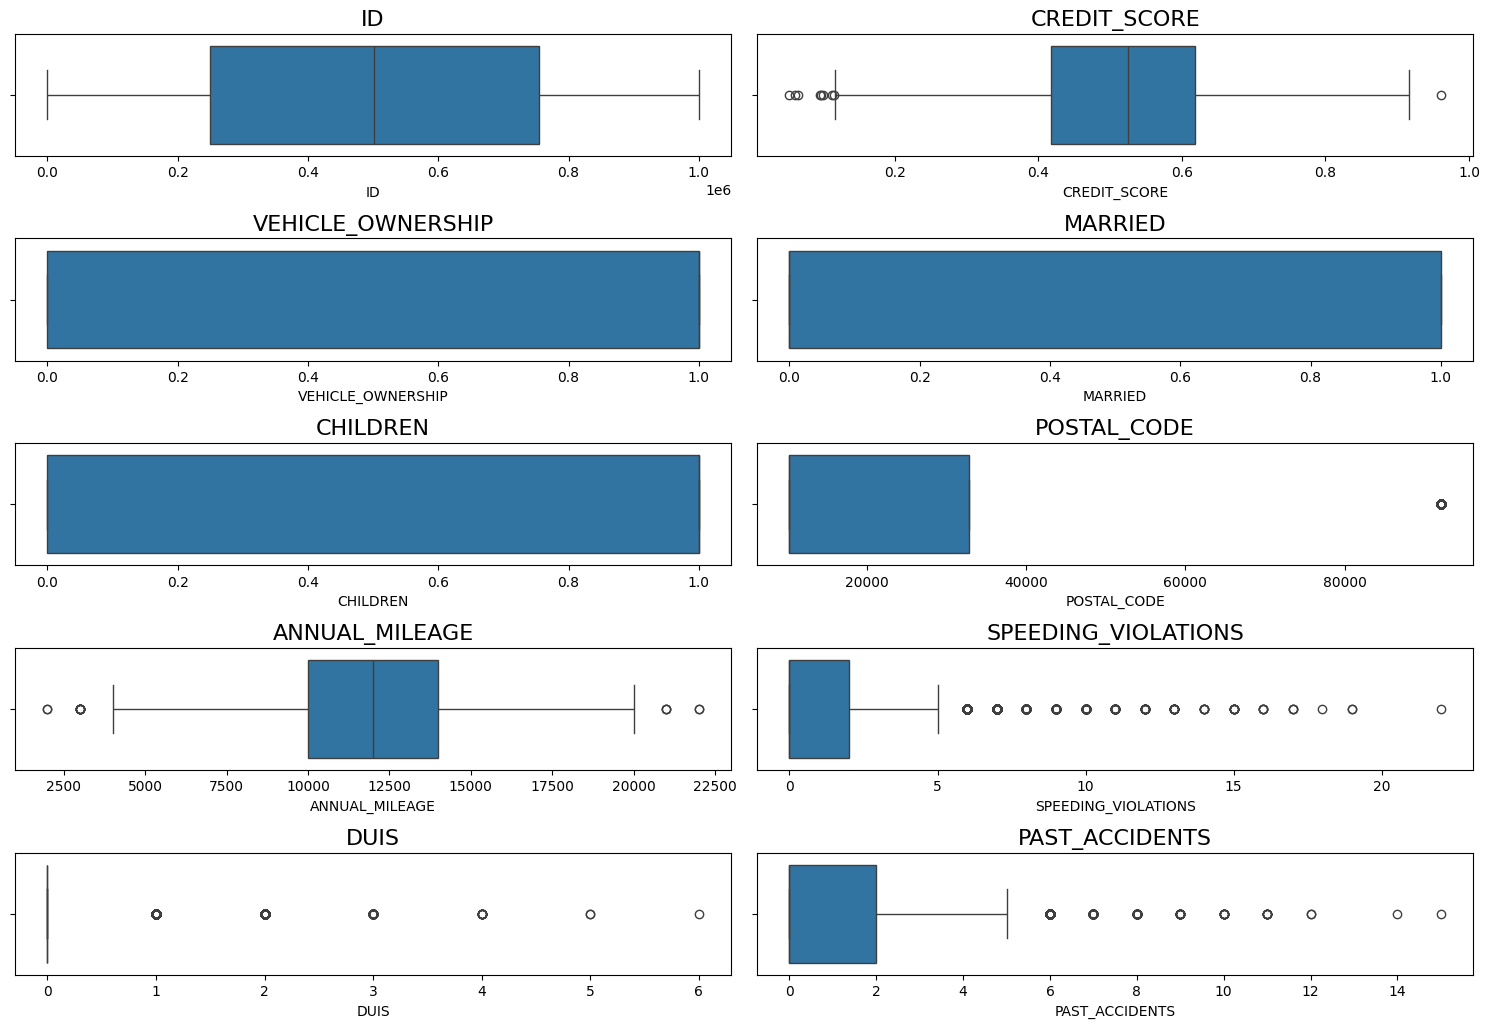

In [120]:
# boxplot
plt.figure(figsize=(15, 12), facecolor='white')
plotnumber = 1
    
for feature in num_feature[:-1]:
    ax = plt.subplot(6,2, plotnumber)
    sns.boxplot(x=feature, data=df);
    plt.title(feature, fontsize=16)
    plt.tight_layout()
    plotnumber += 1

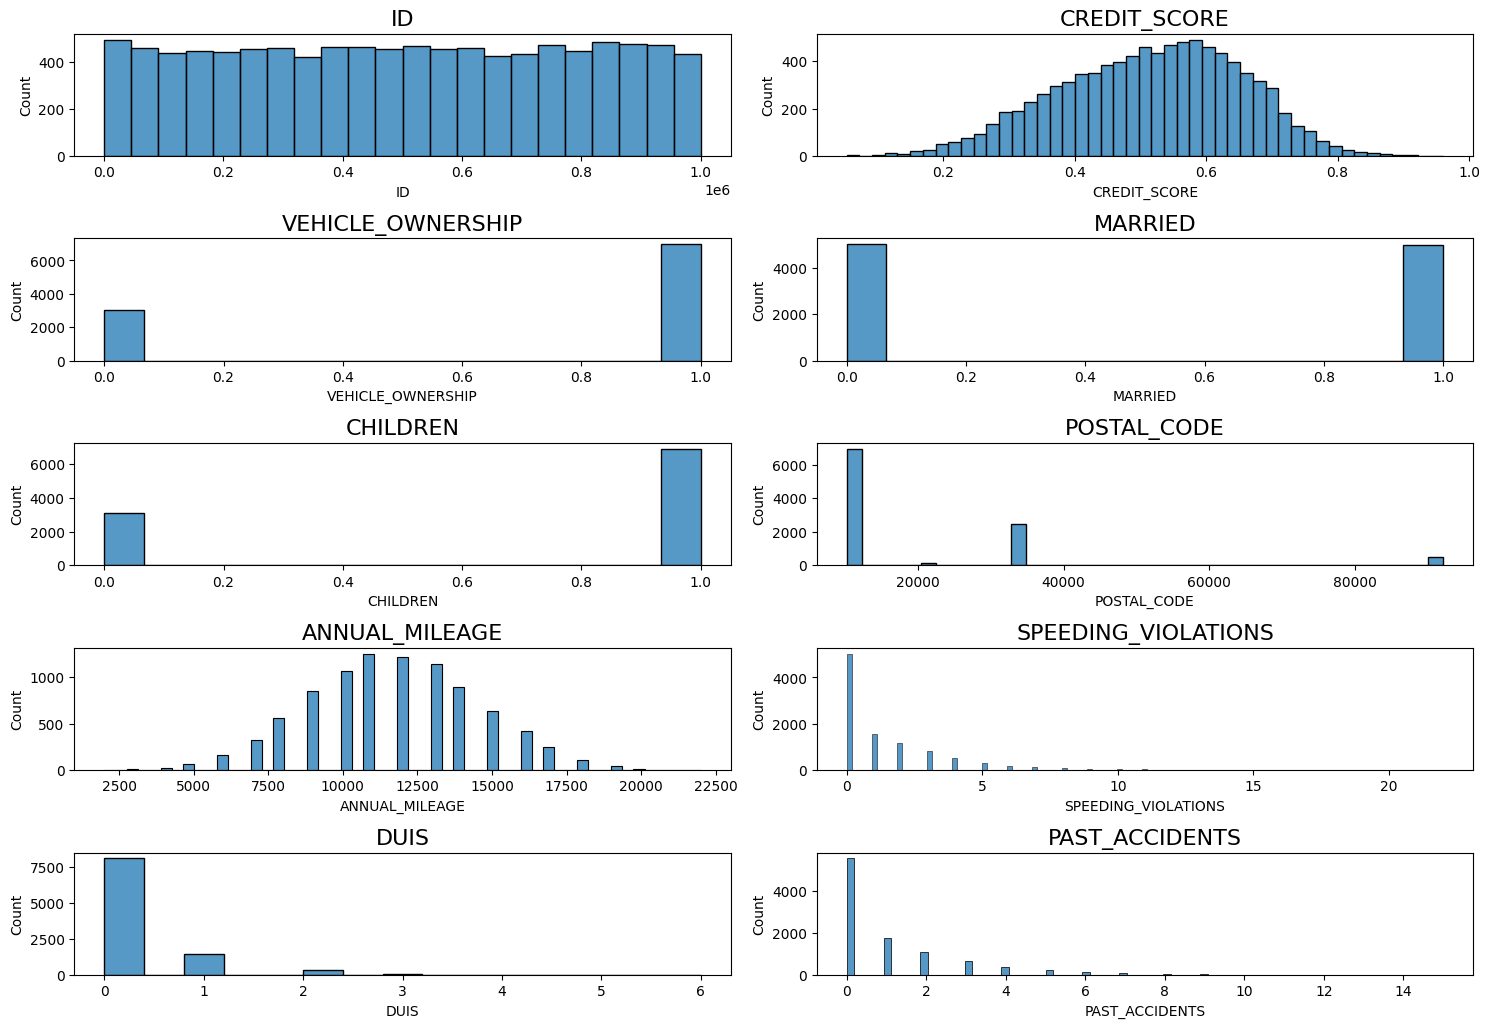

In [121]:
# histplot
plt.figure(figsize=(15, 12), facecolor='white')
plotnumber = 1
    
for feature in num_feature[:-1]:
    ax = plt.subplot(6,2, plotnumber)
    sns.histplot(x=feature, data=df);
    plt.title(feature, fontsize=16)
    plt.tight_layout()
    plotnumber += 1

In [122]:
# mencari nilai lower dan upper fence pada masing-masing kolom

list_lower = []
list_upper = []
number_lower = []
number_inside = []
number_upper = []

for feature in num_feature: 
    IQR = df[feature].quantile(0.75) - df[feature].quantile(0.25)
    lower_fence = df[feature].quantile(0.25) - 1.5*IQR
    upper_fence = df[feature].quantile(0.75) + 1.5*IQR
    list_lower.append(lower_fence)
    list_upper.append(upper_fence)
    number_lower.append(len(df[df[feature]<lower_fence]))
    number_inside.append(len(df[(df[feature]>=lower_fence) & (df[feature]<=upper_fence)]))
    number_upper.append(len(df[df[feature]>upper_fence]))

outliers = pd.DataFrame({
    'Kolom' : num_feature,
    'Lower' : list_lower,
    'Upper' : list_upper,
    '# Lower' : number_lower,
    '# Inside' : number_inside,
    '# Upper' : number_upper,
})

outliers

,Kolom,Lower,Upper,# Lower,# Inside,# Upper
0,ID,-506865.500000,1.510478e+06,0,10000,0
1,CREDIT_SCORE,0.115511,9.199922e-01,8,9009,1
2,VEHICLE_OWNERSHIP,-1.500000,2.500000e+00,0,10000,0
3,MARRIED,-1.500000,2.500000e+00,0,10000,0
4,CHILDREN,-1.500000,2.500000e+00,0,10000,0
5,POSTAL_CODE,-23552.500000,6.655550e+04,0,9516,484
6,ANNUAL_MILEAGE,4000.000000,2.000000e+04,12,9026,5
7,SPEEDING_VIOLATIONS,-3.000000,5.000000e+00,0,9412,588
8,DUIS,0.000000,0.000000e+00,0,8118,1882
9,PAST_ACCIDENTS,-3.000000,5.000000e+00,0,9715,285


### Handling Outliers

Menghilangkan outlier pada kolom credit score dan annual mileage berdasarkan upper dan lower fence

In [123]:
df = df[~((df['CREDIT_SCORE']< outliers['Lower'][1]) | (df['CREDIT_SCORE']> outliers['Upper'][1]))]
df = df[~((df['ANNUAL_MILEAGE']< outliers['Lower'][6]) | (df['ANNUAL_MILEAGE']> outliers['Upper'][6]))]
df.shape

(9974, 19)

Menghilangkan outlier pada kolom speeding violations, duis, dan past accidents  berdasarkan domain knowledge

In [124]:
df['SPEEDING_VIOLATIONS'].value_counts()

SPEEDING_VIOLATIONS
0     5013
1     1542
2     1159
3      829
4      529
5      319
6      188
7      140
8       73
9       49
10      49
11      30
12      19
13      12
15       8
16       4
14       4
17       3
19       2
18       1
22       1
Name: count, dtype: int64

In [125]:
df['DUIS'].value_counts()

DUIS
0    8094
1    1468
2     331
3      68
4      10
5       2
6       1
Name: count, dtype: int64

In [126]:
df['PAST_ACCIDENTS'].value_counts()

PAST_ACCIDENTS
0     5568
1     1779
2     1101
3      643
4      366
5      232
6      144
7       61
8       41
9       19
10       9
11       7
12       2
14       1
15       1
Name: count, dtype: int64

In [127]:
df.shape

(9974, 19)

In [128]:
df = df[df['SPEEDING_VIOLATIONS']<15]
df = df[df['DUIS']<5]
df = df[df['PAST_ACCIDENTS']<10]
df.shape

(9932, 19)

## Define X and y

In [129]:
# define fetures and target
X = df.drop(columns = ['ID', 'OUTCOME'])
y = df['OUTCOME']

## Data Splitting

In [161]:
# data splitting
r_state = 0
X_train, X_test, y_train, y_test = train_test_split(X,y, random_state=r_state, test_size=0.2, stratify=y)

## Preprocessing

### Encoding, Impute Missing Values, Scaling

Preprocess scheme:
  Encoding :
  * Ordinal encoding: 'AGE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME', 'VEHICLE_YEAR'
  * One hot encoding:  'GENDER', 'RACE', 'VEHICLE_TYPE'

  Impute missing values:
  * Isi missing value 'credit_score' dan 'annual_mileage' dengan iterative imputer

  Scaling :
  * Robust Scaler



In [162]:
df['AGE'].unique()

array(['65+', '16-25', '26-39', '40-64'], dtype=object)

In [163]:
df['DRIVING_EXPERIENCE'].unique()

array(['0-9y', '10-19y', '20-29y', '30y+'], dtype=object)

In [164]:
df['EDUCATION'].unique()

array(['high school', 'none', 'university'], dtype=object)

In [165]:
df['INCOME'].unique()

array(['upper class', 'poverty', 'working class', 'middle class'],
      dtype=object)

In [166]:
df['VEHICLE_YEAR'].unique()

array(['after 2015', 'before 2015'], dtype=object)

In [167]:
# mapping untuk ordinal encoder

ordinal_mapping = [
    {'col':'AGE', 'mapping':{None:0, '16-25':1, '26-39':2, '40-64':3, '65+':4}},
    {'col':'DRIVING_EXPERIENCE', 'mapping':{None:0, '0-9y':1, '10-19y':2, '20-29y':3, '30y+':4}},
    {'col':'EDUCATION', 'mapping':{None:0, 'none':1, 'high school':2, 'university':3}},
    {'col':'INCOME', 'mapping':{None:0, 'poverty':1, 'working class':2, 'middle class':3, 'upper class':4}},
    {'col':'VEHICLE_YEAR', 'mapping':{None:0, 'before 2015':1, 'after 2015':2}}
]

In [168]:
# encoding and imputer
transformer = ColumnTransformer([
    ('onehot', OneHotEncoder(drop='first'), ['GENDER', 'RACE', 'VEHICLE_TYPE']),
    ('ordinal', OrdinalEncoder(cols=['AGE','DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME', 'VEHICLE_YEAR'], mapping=ordinal_mapping), ['AGE','DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME', 'VEHICLE_YEAR']),
    ('imp_iter', IterativeImputer(), ['CREDIT_SCORE','ANNUAL_MILEAGE'])
], remainder='passthrough')

transformer

ColumnTransformer(remainder='passthrough',
                  transformers=[('onehot', OneHotEncoder(drop='first'),
                                 ['GENDER', 'RACE', 'VEHICLE_TYPE']),
                                ('ordinal',
                                 OrdinalEncoder(cols=['AGE',
                                                      'DRIVING_EXPERIENCE',
                                                      'EDUCATION', 'INCOME',
                                                      'VEHICLE_YEAR'],
                                                mapping=[{'col': 'AGE',
                                                          'data_type': dtype('O'),
                                                          'mapping': None     0
16-25    1
26-39    2
40-64    3
65+      4
dtype: int64},
                                                         {'col': 'DRIVING_EXPERIENCE',
                                                          'da...
dtype: int64},
                                                         {'col': 'INCOME',
                                                          'data_type': dtype('O'),
                                                          'mapping': None             0
poverty          1
working class    2
middle class     3
upper class      4
dtype: int64},
                                                         {'col': 'VEHICLE_YEAR',
                                                          'data_type': dtype('O'),
                                                          'mapping': None           0
before 2015    1
after 2015     2
dtype: int64}]),
                                 ['AGE', 'DRIVING_EXPERIENCE', 'EDUCATION',
                                  'INCOME', 'VEHICLE_YEAR']),
                                ('imp_iter', IterativeImputer(),
                                 ['CREDIT_SCORE', 'ANNUAL_MILEAGE'])])

In [169]:
# scaling 
scaler = RobustScaler()

## Find Best Benchmark Model

In [170]:
## ML Algo
r_state = 0
logreg = LogisticRegression(solver='liblinear',random_state=r_state)
knn = KNeighborsClassifier(n_neighbors = 3)
tree = DecisionTreeClassifier(max_depth = 3,random_state=r_state)

In [171]:
y.value_counts()/len(y)

OUTCOME
0.0    0.685965
1.0    0.314035
Name: count, dtype: float64

In [172]:
list_mean = []
list_std = []
list_all = []

for model in [logreg, knn, tree]:
    
    pipe_model = Pipeline([
        ('prep', transformer),
        ('scaler', scaler),
        ('algo', model)
    ])

    cv_score = cross_val_score(
        estimator= pipe_model,
        X= X_train,
        y= y_train,
        cv= 5,
        scoring= 'f1'
    )

    # print(cv_score, model)

    list_mean.append(cv_score.mean())
    list_std.append(cv_score.std())
    list_all.append(cv_score.round(2))

pd.DataFrame({
    'algo':[logreg, knn, tree],
    'mean_f1': list_mean,
    'std': list_std,
    'all score': list_all
})

,algo,mean_f1,std,all score
0,"LogisticRegression(random_state=0, solver='liblinear')",0.739126,0.010196,"[0.73, 0.75, 0.75, 0.74, 0.72]"
1,KNeighborsClassifier(n_neighbors=3),0.658368,0.011906,"[0.67, 0.67, 0.65, 0.66, 0.64]"
2,"DecisionTreeClassifier(max_depth=3, random_state=0)",0.694792,0.011307,"[0.69, 0.7, 0.69, 0.72, 0.68]"


**Summary**

- Benchmark Model terbaik adalah LogisticRegression karena rata-rata f1-nya paling tinggi dan cukup stabil
- Kita akan melakukan Hyperparameter Logistic Regression

## Hyperparameter Tuning with GridSearch CV

In [173]:
# hyperparameter untuk Logistic Regression
hyperparam_space = {
    'algo__solver':['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga'],
    'scaler': [RobustScaler(),MinMaxScaler(), StandardScaler()]
}

# pipeline
pipe_model = Pipeline([
        ('prep', transformer),
        ('scaler', scaler),
        ('algo', logreg)           # benchmark model terbaik
    ])

# gridsearch
gridsearch_tuning = GridSearchCV(
    estimator= pipe_model,
    param_grid= hyperparam_space,
    cv= 5,
    scoring='f1',
    n_jobs= -1
)

gridsearch_tuning.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('prep',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('onehot',
                                                                         OneHotEncoder(drop='first'),
                                                                         ['GENDER',
                                                                          'RACE',
                                                                          'VEHICLE_TYPE']),
                                                                        ('ordinal',
                                                                         OrdinalEncoder(cols=['AGE',
                                                                                              'DRIVING_EXPERIENCE',
                                                                                              'EDUCATION',
                                                                                              'INCOME',
                                                                                              'VEHICLE_YEAR'],
                                                                                        mapping=[{'col': 'AGE',
                                                                                                  'data_type': dtype('O'),
                                                                                                  'mapping': None     0
16-25    1
26-39    2
40...
                                                                          'EDUCATION',
                                                                          'INCOME',
                                                                          'VEHICLE_YEAR']),
                                                                        ('imp_iter',
                                                                         IterativeImputer(),
                                                                         ['CREDIT_SCORE',
                                                                          'ANNUAL_MILEAGE'])])),
                                       ('scaler', RobustScaler()),
                                       ('algo',
                                        LogisticRegression(random_state=0,
                                                           solver='liblinear'))]),
             n_jobs=-1,
             param_grid={'algo__solver': ['newton-cg', 'lbfgs', 'liblinear',
                                          'sag', 'saga'],
                         'scaler': [RobustScaler(), MinMaxScaler(),
                                    StandardScaler()]},
             scoring='f1')

In [174]:
best_model_grid = gridsearch_tuning.best_estimator_

In [175]:
gridsearch_tuning.best_params_

{'algo__solver': 'newton-cg', 'scaler': RobustScaler()}

In [176]:
gridsearch_tuning.best_score_

0.7395848892458176

Performa model setelah dilakukan hyperparameter tuning {'algo__solver': 'newton-cg', 'scaler': RobustScaler()}
- f1 benchmark model: 0.73912
- f1 setelah tuning: 0.73958

## Predict to Test Set (without Hyperparameter Tuning)

In [192]:
pipe_model

Pipeline(steps=[('prep',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehot',
                                                  OneHotEncoder(drop='first'),
                                                  ['GENDER', 'RACE',
                                                   'VEHICLE_TYPE']),
                                                 ('ordinal',
                                                  OrdinalEncoder(cols=['AGE',
                                                                       'DRIVING_EXPERIENCE',
                                                                       'EDUCATION',
                                                                       'INCOME',
                                                                       'VEHICLE_YEAR'],
                                                                 mapping=[{'col': 'AGE',
                                                                           'data_type': dtype('O'),
                                                                           'mapping': None     0
16-25    1
26-39    2
40-64    3
65+      4
dtype: int64},
                                                                          {'col':...
middle class     3
upper class      4
dtype: int64},
                                                                          {'col': 'VEHICLE_YEAR',
                                                                           'data_type': dtype('O'),
                                                                           'mapping': None           0
before 2015    1
after 2015     2
dtype: int64}]),
                                                  ['AGE', 'DRIVING_EXPERIENCE',
                                                   'EDUCATION', 'INCOME',
                                                   'VEHICLE_YEAR']),
                                                 ('imp_iter',
                                                  IterativeImputer(),
                                                  ['CREDIT_SCORE',
                                                   'ANNUAL_MILEAGE'])])),
                ('scaler', RobustScaler()),
                ('algo',
                 LogisticRegression(random_state=0, solver='liblinear'))])

In [193]:
pipe_model.fit(X_train, y_train)

y_pred = pipe_model.predict(X_test)
f1_score(y_test, y_pred)

0.7512355848434926

## Predict to Test Set (with Hyperparameter Tuning)

In [194]:
best_model_grid

Pipeline(steps=[('prep',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehot',
                                                  OneHotEncoder(drop='first'),
                                                  ['GENDER', 'RACE',
                                                   'VEHICLE_TYPE']),
                                                 ('ordinal',
                                                  OrdinalEncoder(cols=['AGE',
                                                                       'DRIVING_EXPERIENCE',
                                                                       'EDUCATION',
                                                                       'INCOME',
                                                                       'VEHICLE_YEAR'],
                                                                 mapping=[{'col': 'AGE',
                                                                           'data_type': dtype('O'),
                                                                           'mapping': None     0
16-25    1
26-39    2
40-64    3
65+      4
dtype: int64},
                                                                          {'col':...
middle class     3
upper class      4
dtype: int64},
                                                                          {'col': 'VEHICLE_YEAR',
                                                                           'data_type': dtype('O'),
                                                                           'mapping': None           0
before 2015    1
after 2015     2
dtype: int64}]),
                                                  ['AGE', 'DRIVING_EXPERIENCE',
                                                   'EDUCATION', 'INCOME',
                                                   'VEHICLE_YEAR']),
                                                 ('imp_iter',
                                                  IterativeImputer(),
                                                  ['CREDIT_SCORE',
                                                   'ANNUAL_MILEAGE'])])),
                ('scaler', RobustScaler()),
                ('algo',
                 LogisticRegression(random_state=0, solver='newton-cg'))])

In [195]:
best_model_grid.fit(X_train, y_train)

y_pred = best_model_grid.predict(X_test)
f1_score(y_test, y_pred)

0.7502061005770816

Performa model pada test set
- f1_score benchmark model: 0.7512
- f1_score setelah tuning: 0.75020

In [196]:
transformer.transformers_

[('onehot', OneHotEncoder(drop='first'), ['GENDER', 'RACE', 'VEHICLE_TYPE']),
 ('ordinal',
  OrdinalEncoder(cols=['AGE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME',
                       'VEHICLE_YEAR'],
                 mapping=[{'col': 'AGE', 'data_type': dtype('O'),
                           'mapping': None     0
  16-25    1
  26-39    2
  40-64    3
  65+      4
  dtype: int64},
                          {'col': 'DRIVING_EXPERIENCE', 'data_type': dtype('O'),
                           'mapping': None      0
  0-9y      1
  10-19y    2
  20-29y    3
  30y+      4
  dtype: int64},
                          {'col': 'EDUCATION', 'data_type': dtype('O'),
                           'mapping': None           0
  none           1
  high school    2
  university     3
  dtype: int64},
                          {'col': 'INCOME', 'data_type': dtype('O'),
                           'mapping': None             0
  poverty          1
  working class    2
  middle class     3
  upper class   

In [197]:
feature_onehot = transformer.transformers_[0][2]
feature_ordinal = transformer.transformers_[1][2]
feature_imputer = transformer.transformers_[2][2]
feature_numerical = list(X_train.columns[transformer.transformers_[3][2]])

feature_name = feature_onehot + feature_ordinal + feature_imputer + feature_numerical 


In [198]:
best_model_grid[2].coef_

array([[ 0.9552073 , -0.10536963,  0.00959134,  0.00550331, -3.36266694,
        -0.02385343, -0.13491759, -1.67961228, -0.01379823,  0.20985757,
        -1.61763054, -0.40155353, -0.16519047,  0.49976942,  0.1374819 ,
         0.06812592, -0.30357268]])

In [199]:
df_coef = pd.DataFrame({
    'feature' : feature_name,
    'coef' : np.abs(best_model_grid[2].coef_[0])
}).sort_values('coef',ascending=False)

df_coef

,feature,coef
4,DRIVING_EXPERIENCE,3.362667
7,VEHICLE_YEAR,1.679612
10,VEHICLE_OWNERSHIP,1.617631
0,GENDER,0.955207
13,POSTAL_CODE,0.499769
11,MARRIED,0.401554
16,PAST_ACCIDENTS,0.303573
9,ANNUAL_MILEAGE,0.209858
12,CHILDREN,0.165190
14,SPEEDING_VIOLATIONS,0.137482


### Modeling (Voting)

In [200]:
# define base learner
logreg= LogisticRegression(solver='sag',random_state=r_state)
# logreg= LogisticRegression(solver='newton-cg',random_state=r_state)
# logreg= LogisticRegression(solver='liblinear',random_state=r_state)
knn = KNeighborsClassifier()
tree = DecisionTreeClassifier(max_depth=5, random_state=r_state)

#pipe_logreg
pipe_logreg = Pipeline([
        ('prep', transformer),
        ('scaler', StandardScaler()),
        # ('scaler', RobustScaler()),
        ('algo', logreg)           
    ])

#pipe_knn
pipe_knn = Pipeline([
        ('prep', transformer),
        ('scaler', scaler),
        ('algo', knn)           
    ])

#pipe_tree
pipe_tree = Pipeline([
        ('prep', transformer),
        ('algo', tree)           
    ])


# ensemble (voting)
voting_clf = VotingClassifier([
    ('clf1', pipe_logreg),
    ('clf2', pipe_knn),
    ('clf3', pipe_tree)
], voting='soft')

# fitting
voting_clf.fit(X_train, y_train)

VotingClassifier(estimators=[('clf1',
                              Pipeline(steps=[('prep',
                                               ColumnTransformer(remainder='passthrough',
                                                                 transformers=[('onehot',
                                                                                OneHotEncoder(drop='first'),
                                                                                ['GENDER',
                                                                                 'RACE',
                                                                                 'VEHICLE_TYPE']),
                                                                               ('ordinal',
                                                                                OrdinalEncoder(cols=['AGE',
                                                                                                     'DRIVING_EXPERIENCE',
                                                                                                     'EDUCATION',
                                                                                                     'INCOME',
                                                                                                     'VEHICLE_YEAR'],
                                                                                               mapping=[{'col': 'AGE',
                                                                                                         'data_type': dtype('O'),
                                                                                                         'mapping': None     0
16-25...
working class    2
middle class     3
upper class      4
dtype: int64},
                                                                                                        {'col': 'VEHICLE_YEAR',
                                                                                                         'data_type': dtype('O'),
                                                                                                         'mapping': None           0
before 2015    1
after 2015     2
dtype: int64}]),
                                                                                ['AGE',
                                                                                 'DRIVING_EXPERIENCE',
                                                                                 'EDUCATION',
                                                                                 'INCOME',
                                                                                 'VEHICLE_YEAR']),
                                                                               ('imp_iter',
                                                                                IterativeImputer(),
                                                                                ['CREDIT_SCORE',
                                                                                 'ANNUAL_MILEAGE'])])),
                                              ('algo',
                                               DecisionTreeClassifier(max_depth=5,
                                                                      random_state=0))]))],
                 voting='soft')

In [201]:
y_pred_voting = voting_clf.predict(X_test)
f1_score(y_test, y_pred_voting)

0.7481296758104738

## Stacking

In [202]:
from sklearn.ensemble import StackingClassifier
# define base learner
logreg= LogisticRegression(solver='sag',random_state=r_state)
# logreg= LogisticRegression(solver='newton-cg',random_state=r_state)
# logreg= LogisticRegression(solver='liblinear',random_state=r_state)
knn = KNeighborsClassifier()
tree = DecisionTreeClassifier(max_depth=5, random_state=r_state)\

#pipe_logreg
pipe_logreg = Pipeline([
        ('prep', transformer),
        ('scaler', StandardScaler()),
        # ('scaler', RobustScaler()),
        ('algo', logreg)           
    ])

#pipe_knn
pipe_knn = Pipeline([
        ('prep', transformer),
        ('scaler', scaler),
        ('algo', knn)           
    ])

#pipe_tree
pipe_tree = Pipeline([
        ('prep', transformer),
        ('algo', tree)           
    ])


# ensemble (stacking)
stacking_clf = StackingClassifier([
    ('clf1', pipe_logreg),
    ('clf2', pipe_knn),
    ('clf3', pipe_tree)
], final_estimator=tree)

# fitting
stacking_clf.fit(X_train, y_train)

StackingClassifier(estimators=[('clf1',
                                Pipeline(steps=[('prep',
                                                 ColumnTransformer(remainder='passthrough',
                                                                   transformers=[('onehot',
                                                                                  OneHotEncoder(drop='first'),
                                                                                  ['GENDER',
                                                                                   'RACE',
                                                                                   'VEHICLE_TYPE']),
                                                                                 ('ordinal',
                                                                                  OrdinalEncoder(cols=['AGE',
                                                                                                       'DRIVING_EXPERIENCE',
                                                                                                       'EDUCATION',
                                                                                                       'INCOME',
                                                                                                       'VEHICLE_YEAR'],
                                                                                                 mapping=[{'col': 'AGE',
                                                                                                           'data_type': dtype('O'),
                                                                                                           'mapping': None     0
16-...
                                                                                                          {'col': 'VEHICLE_YEAR',
                                                                                                           'data_type': dtype('O'),
                                                                                                           'mapping': None           0
before 2015    1
after 2015     2
dtype: int64}]),
                                                                                  ['AGE',
                                                                                   'DRIVING_EXPERIENCE',
                                                                                   'EDUCATION',
                                                                                   'INCOME',
                                                                                   'VEHICLE_YEAR']),
                                                                                 ('imp_iter',
                                                                                  IterativeImputer(),
                                                                                  ['CREDIT_SCORE',
                                                                                   'ANNUAL_MILEAGE'])])),
                                                ('algo',
                                                 DecisionTreeClassifier(max_depth=5,
                                                                        random_state=0))]))],
                   final_estimator=DecisionTreeClassifier(max_depth=5,
                                                          random_state=0))

In [203]:
y_pred_stacking = stacking_clf.predict(X_test)
f1_score(y_test, y_pred_stacking)

0.7736757624398074

Performa model pada test set
- f1_score benchmark model: 0.7512
- f1_score setelah tuning: 0.75020
- f1_score voting: 0.74812
- f1_score stacking: 0.77367

In [204]:
print(classification_report(y_test, y_pred_stacking))

              precision    recall  f1-score   support

         0.0       0.90      0.90      0.90      1363
         1.0       0.77      0.77      0.77       624

    accuracy                           0.86      1987
   macro avg       0.84      0.83      0.84      1987
weighted avg       0.86      0.86      0.86      1987



In [205]:
# score
print('Precision:', precision_score(y_test, y_pred_stacking))
print('Recall:', recall_score(y_test, y_pred_stacking))
print('F1 score:', f1_score(y_test, y_pred_stacking))
print('Accuracy:', accuracy_score(y_test, y_pred_stacking))

Precision: 0.77491961414791
Recall: 0.7724358974358975
F1 score: 0.7736757624398074
Accuracy: 0.8580775037745345


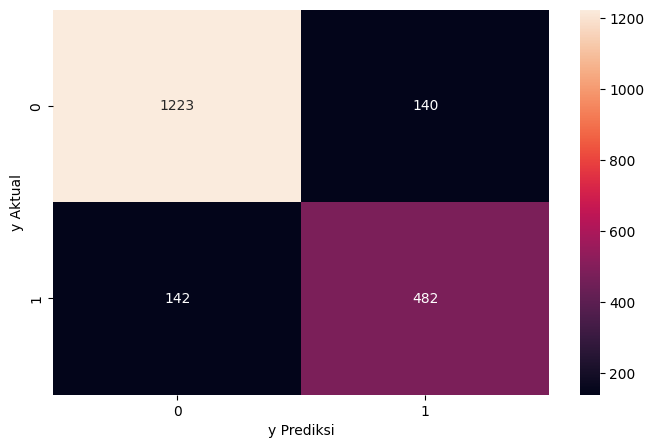

In [206]:
f, ax = plt.subplots(figsize=(8, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_stacking), annot=True, fmt='.0f', ax=ax)

plt.xlabel('y Prediksi')
plt.ylabel('y Aktual');